# Medical Insurance Cost Analysis 

## Project overview

Medical insurance charges vary across individuals. This project explores how age, body mass index (BMI), smoking status, and other recorded characteristics are associated with insurance charges. Regression models are developed and compared to assess how well these features explain and predict costs.

### Project objectives

- Load the insurance dataset into a Pandas DataFrame.
- Clean the data and handle missing values.
- Explore relationships between insurance charges and the other recorded attributes.
- Develop single-variable and multiple-variable linear regression models to predict charges.
- Use polynomial features and Ridge regression to assess and refine model performance.

### Dataset

The IBM Skills Network practice dataset contains **2,772 records** and seven columns. The original CSV has no header row, so column names are assigned after loading.

| Parameter |Description| Content type |
|---|----|---|
|age| Age in years| integer |
|gender| Male or Female|integer (1 or 2)|
| bmi | Body mass index | float |
|no_of_children| Number of children | integer|
|smoker| Whether smoker or not | integer (0 or 1)|
|region| Which US region - NW, NE, SW, SE | integer (1,2,3 or 4 respectively)| 
|charges| Annual Insurance charges in USD | float|

### Tools used

- **Python:** Analysis and modeling in Jupyter Notebook.
- **Pandas and NumPy:** Data loading, cleaning, and numerical operations.
- **Matplotlib and Seaborn:** Visualizing relationships and distributions.
- **Scikit-learn:** Linear regression, polynomial features, Ridge regression, and model evaluation.



## 1. Import the dataset

### Import Python libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split

Load the dataset into a Pandas DataFrame. Since the CSV has no column headers, display the first 10 rows to check that it loaded correctly.

In [11]:
filepath = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/medical_insurance_dataset.csv"

df = pd.read_csv(filepath, header=None)
print(df.head(10))

    0  1       2  3  4  5            6
0  19  1  27.900  0  1  3  16884.92400
1  18  2  33.770  1  0  4   1725.55230
2  28  2  33.000  3  0  4   4449.46200
3  33  2  22.705  0  0  1  21984.47061
4  32  2  28.880  0  0  1   3866.85520
5  31  1  25.740  0  ?  4   3756.62160
6  46  1  33.440  1  0  4   8240.58960
7  37  1  27.740  3  0  1   7281.50560
8  37  2  29.830  2  0  2   6406.41070
9  60  1  25.840  0  0  1  28923.13692


Assign the column names provided in the dataset description.

In [13]:
headers = ["Age", "Gender", "BMI", "No_of_Children", "Smoker", "Region", "Charges"]

df.columns = headers

print(df.head(10))

  Age  Gender     BMI  No_of_Children Smoker  Region      Charges
0  19       1  27.900               0      1       3  16884.92400
1  18       2  33.770               1      0       4   1725.55230
2  28       2  33.000               3      0       4   4449.46200
3  33       2  22.705               0      0       1  21984.47061
4  32       2  28.880               0      0       1   3866.85520
5  31       1  25.740               0      ?       4   3756.62160
6  46       1  33.440               1      0       4   8240.58960
7  37       1  27.740               3      0       1   7281.50560
8  37       2  29.830               2      0       2   6406.41070
9  60       1  25.840               0      0       1  28923.13692


Replace entries marked `?` with `NaN` so missing values can be identified.

In [15]:
df.replace("?", np.nan, inplace=True)

print(df.head(10))

  Age  Gender     BMI  No_of_Children Smoker  Region      Charges
0  19       1  27.900               0      1       3  16884.92400
1  18       2  33.770               1      0       4   1725.55230
2  28       2  33.000               3      0       4   4449.46200
3  33       2  22.705               0      0       1  21984.47061
4  32       2  28.880               0      0       1   3866.85520
5  31       1  25.740               0    NaN       4   3756.62160
6  46       1  33.440               1      0       4   8240.58960
7  37       1  27.740               3      0       1   7281.50560
8  37       2  29.830               2      0       2   6406.41070
9  60       1  25.840               0      0       1  28923.13692


## 2. Data wrangling

Use `df.info()` to check the column types and identify missing values.

In [21]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             2768 non-null   object 
 1   Gender          2772 non-null   int64  
 2   BMI             2772 non-null   float64
 3   No_of_Children  2772 non-null   int64  
 4   Smoker          2765 non-null   object 
 5   Region          2772 non-null   int64  
 6   Charges         2772 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 151.7+ KB
None


### Handle missing values

- Replace missing values in continuous variables, such as age, with the column mean.
- Replace missing values in categorical variables, such as smoking status, with the most frequent value.
- Update the data types of the affected columns.
- Use `df.info()` to confirm the changes.

In [27]:
# Fill missing smoking status with the most frequent recorded value.
is_smoker = df["Smoker"].value_counts().idxmax()
df["Smoker"] = df["Smoker"].fillna(is_smoker)

# Fill missing ages with the mean of the available ages.
mean_age = df["Age"].astype("float").mean()
df["Age"] = df["Age"].fillna(mean_age)

# Convert the completed columns to integers and confirm the result.
df[["Age", "Smoker"]] = df[["Age", "Smoker"]].astype("int")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             2772 non-null   int32  
 1   Gender          2772 non-null   int64  
 2   BMI             2772 non-null   float64
 3   No_of_Children  2772 non-null   int64  
 4   Smoker          2772 non-null   int32  
 5   Region          2772 non-null   int64  
 6   Charges         2772 non-null   float64
dtypes: float64(2), int32(2), int64(3)
memory usage: 130.1 KB


Round the values in `Charges` to two decimal places and display the updated data.

In [29]:

df[["Charges"]] = np.round(df[["Charges"]], 2)
print(df.head())


   Age  Gender     BMI  No_of_Children  Smoker  Region   Charges
0   19       1  27.900               0       1       3  16884.92
1   18       2  33.770               1       0       4   1725.55
2   28       2  33.000               3       0       4   4449.46
3   33       2  22.705               0       0       1  21984.47
4   32       2  28.880               0       0       1   3866.86


## 3. Exploratory data analysis (EDA)

Create a regression plot to examine the relationship between `BMI` and `Charges`.

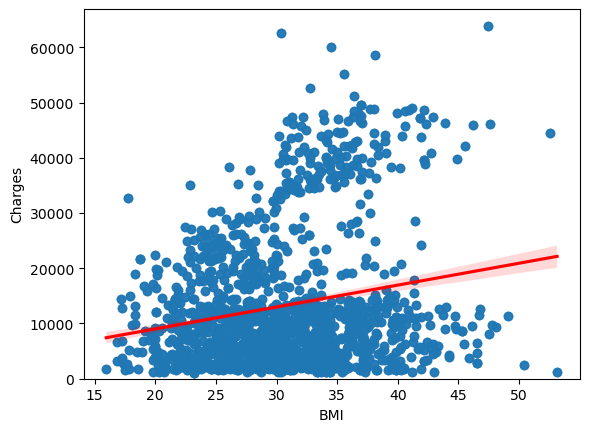

In [39]:

sns.regplot(x="BMI", y="Charges", data=df, line_kws={"color": "red"})
plt.ylim(0,)
plt.show()


Create a box plot to compare `Charges` across smoking-status groups.

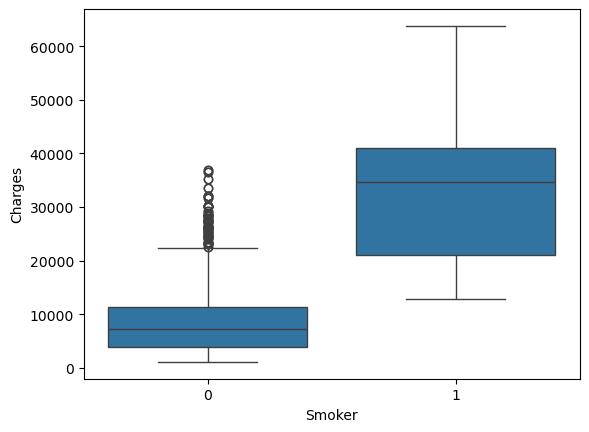

In [41]:

sns.boxplot(x="Smoker", y="Charges", data=df)
plt.show()


Print the correlation matrix to examine relationships between the dataset variables.

In [43]:

print(df.corr())


                     Age    Gender       BMI  No_of_Children    Smoker  \
Age             1.000000 -0.026046  0.113048        0.037574 -0.023286   
Gender         -0.026046  1.000000  0.042924        0.016020  0.082326   
BMI             0.113048  0.042924  1.000000       -0.001492  0.011489   
No_of_Children  0.037574  0.016020 -0.001492        1.000000  0.006362   
Smoker         -0.023286  0.082326  0.011489        0.006362  1.000000   
Region         -0.007167  0.022213  0.271119       -0.025717  0.054077   
Charges         0.298624  0.062837  0.199846        0.066442  0.788783   

                  Region   Charges  
Age            -0.007167  0.298624  
Gender          0.022213  0.062837  
BMI             0.271119  0.199846  
No_of_Children -0.025717  0.066442  
Smoker          0.054077  0.788783  
Region          1.000000  0.054058  
Charges         0.054058  1.000000  


### Key findings from exploratory analysis

- **Smoking status:** The strongest reported positive correlation with charges (**r ≈ 0.789**). The box plot also shows higher charges overall for the group coded as smokers.
- **Age and BMI:** Weaker positive correlations with charges (**r ≈ 0.299** for age and **r ≈ 0.200** for BMI). Charges vary considerably even among individuals with similar BMI values.

These relationships describe patterns in the dataset and do not establish causation.


## 4. Model development

Fit a linear regression model to predict `Charges` using only `Smoker`. Print its R² score.

In [48]:

X = df[["Smoker"]]
Y = df["Charges"]

lm = LinearRegression()
lm.fit(X, Y)

print(lm.score(X, Y))


0.6221791733924185


Fit a linear regression model to predict `Charges` using all six other attributes. Print the R² score and compare it with the single-variable model.

In [50]:

Z = df[["Age", "Gender", "BMI", "No_of_Children", "Smoker", "Region"]]

lm.fit(Z, Y)

print(lm.score(Z, Y))


0.7504083820289634


Create a prediction pipeline using `StandardScaler()`, `PolynomialFeatures()`, and `LinearRegression()` with all six predictors. Print the R² score and compare model performance.

In [52]:

Input = [
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(include_bias=False)),
    ("model", LinearRegression())
]

pipe = Pipeline(Input)
Z = Z.astype(float)
pipe.fit(Z, Y)
ypipe = pipe.predict(Z)
print(r2_score(Y, ypipe))


0.8452168732325275


### Comparing the models

Three approaches were compared: linear regression using smoking status, linear regression using all six predictors, and a polynomial regression pipeline.

| Model | Training R² |
|---|---:|
| Linear regression using smoking status | 0.6222 |
| Linear regression using all six predictors | 0.7504 |
| Standardized polynomial regression pipeline | 0.8452 |

Including additional features improved the training fit. The polynomial pipeline achieved the highest training R², but training results alone cannot show how accurately a model predicts new observations. The next section evaluates Ridge regression using a separate test set.


## 5. Model refinement

Split the dataset into training and testing subsets, reserving 20% of the data for testing.

In [57]:
x_train, x_test, y_train, y_test = train_test_split(
    Z, Y, test_size=0.2, random_state=1
)

In [59]:
print("Training records:", x_train.shape[0])
print("Testing records:", x_test.shape[0])

Training records: 2217
Testing records: 555


Initialize a Ridge regression model with `alpha=0.1`. Fit it using the training data and print the R² score for the testing data.

In [61]:

RidgeModel = Ridge(alpha=0.1)

RidgeModel.fit(x_train, y_train)

yhat = RidgeModel.predict(x_test)

print(r2_score(y_test, yhat))


0.6760807731582408


Apply a degree-2 polynomial transformation to the features. Fit the Ridge regression model on the transformed training data and print its R² score using the transformed testing data.

In [63]:

pr = PolynomialFeatures(degree=2)

x_train_pr = pr.fit_transform(x_train)

x_test_pr = pr.transform(x_test)

RidgeModel.fit(x_train_pr, y_train)

y_hat = RidgeModel.predict(x_test_pr)

print(r2_score(y_test, y_hat))


0.7835631107608146


### Test-set results and conclusion

| Model | Test R² |
|---|---:|
| Ridge regression (`alpha=0.1`) | 0.6761 |
| Polynomial Ridge regression (degree 2, `alpha=0.1`) | 0.7836 |

The Ridge Regression model achieved an R² score of 0.6761 (67.61%), while Polynomial Ridge Regression achieved 0.7836 (78.36%). This shows that adding polynomial features improved the model's performance on the test data by approximately 10.75 percentage points.

**Conclusion:** The analysis showed that smoking status was an important factor associated with medical insurance charges. Including additional features such as age, BMI, and other recorded characteristics improved the regression model's fitt.

**Limitations and next steps:** The results were obtained using a single training and testing split. Future improvements could include cross-validation, adjusting model parameters, and evaluating prediction errors  to better assess model reliability.

---

**Acknowledgment:** This project was completed as part of the IBM Data Analyst Professional Certificate on Coursera, using materials provided by IBM Skills Network.